# Gent optimizer comparison: SGD + Momentum, Adam, L-BFGS
Same stress model and energy network as the original notebook. Hard-concrete gates are removed only for a deterministic, fair optimizer comparison.


In [17]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [18]:
# Material Parameters
mu = 0.8
jm = 40.0
Identity = torch.eye(3)


In [19]:
# Gent Stress Function
def gent_stress_function(lamda, mu, jm):
    I1 = lamda**2 + 2/lamda
    stress = mu * (lamda - 1/lamda**2) / (1 - (I1 - 3)/jm)
    return stress


In [20]:
def deformation_gradient(lamda):
    diagonal_values = torch.stack([
        lamda,
        lamda**(-0.5),
        lamda**(-0.5)
    ], dim=-1)

    return torch.diag_embed(diagonal_values)


In [21]:
def frobenius_norm(F):
    return torch.sqrt(
        torch.sum((F - Identity)**2, dim=(-2, -1))
    )


In [22]:
def add_noise(P_true_train,eta_min,eta_max,lamda):
    P_char = torch.max(torch.abs(P_true_train))
    noise_sd_min = eta_min * P_char
    noise_sd_max = eta_max * P_char
    F = deformation_gradient(lamda)
    F_lambdamax = deformation_gradient(torch.max(lamda))
    q = 2.0
    t = frobenius_norm(F)
    ksy = torch.randn_like(P_true_train)
    conditional_noise_variance = torch.square(noise_sd_min) + (torch.square(noise_sd_max) - torch.square(noise_sd_min)) * ((t / frobenius_norm(F_lambdamax))**q)
    noise = torch.sqrt(conditional_noise_variance) * ksy
    return noise,conditional_noise_variance


In [23]:
# Synthetic Data Generation
def generate_synthetic_data(num_samples, lamda_min, lamda_max,eta_min,eta_max):
    lamda_train = torch.linspace(lamda_min, lamda_max, num_samples)
    I1_train = lamda_train**2 + 2/lamda_train
    P_true_train = gent_stress_function(lamda_train, mu, jm)   
    noise,conditional_noise_variance = add_noise(P_true_train,eta_min,eta_max,lamda_train)
    Y_train = P_true_train + noise
    Y_train = Y_train.reshape(-1, 1)
    lamda_train =lamda_train.reshape(-1, 1)
    I1_train = I1_train.reshape(-1, 1)
    x = torch.cat((lamda_train, I1_train,Y_train), dim=1)
    return x,conditional_noise_variance


In [24]:
import time
import copy
import numpy as np

torch.set_num_threads(1)  # makes CPU timings more consistent

torch.manual_seed(42)
x, conditional_noise_variance = generate_synthetic_data(
    num_samples=50000, lamda_min=1.0, lamda_max=4.0,
    eta_min=0.005, eta_max=0.03
)

# Change these three settings to run longer or adjust the target
num_epochs = 10000
target_rmse = 0.15
m = 10


In [25]:
# Same energy formula as the original NeuralNetwork, without random sparsity gates
class NeuralNetwork(nn.Module):
    def __init__(self, m=10):
        super().__init__()
        self.a = nn.Parameter(torch.randn(1))
        self.c = nn.Parameter(torch.randn(m))
        self.w = nn.Parameter(torch.randn(m))
        self.b = nn.Parameter(torch.randn(m))

    def forward(self, I1):
        a = F.softplus(self.a)
        c = F.softplus(self.c)
        w = F.softplus(self.w)
        b = self.b
        x = I1 - 3
        hidden = F.softplus(x * w + b) - F.softplus(b)
        psi = a * x + torch.sum(c * hidden, dim=-1, keepdim=True)
        return psi


In [26]:
# Calculate stress from the learned strain energy, as in your original code
def predict_stress(model, lamda):
    I1 = (lamda**2 + 2/lamda).detach().clone().requires_grad_(True)
    psi = model(I1)
    dpsi_dI1 = torch.autograd.grad(
        psi, I1, grad_outputs=torch.ones_like(psi), create_graph=True
    )[0]
    return 2 * dpsi_dI1 * (lamda - 1/lamda**2)

def loss_function(model, data):
    lamda = data[:, 0:1]
    Y_train = data[:, 2:3]
    P_pred = predict_stress(model, lamda)
    return torch.mean((P_pred - Y_train)**2)

# Evaluate against noiseless Gent stress so the target is comparable across optimizers
def stress_rmse(model, lamda):
    with torch.enable_grad():
        P_pred = predict_stress(model, lamda)
    P_true = gent_stress_function(lamda, mu, jm)
    return torch.sqrt(torch.mean((P_pred - P_true)**2)).item()


In [27]:
# Same initialization and data for all three optimizers
initial_model = NeuralNetwork(m=m)
initial_weights = copy.deepcopy(initial_model.state_dict())

optimizers = {
    'SGD + Momentum': lambda p: torch.optim.SGD(p, lr=0.0005, momentum=0.9),
    'Adam': lambda p: torch.optim.Adam(p, lr=0.01),
    'L-BFGS (Quasi-Newton)': lambda p: torch.optim.LBFGS(
        p, lr=0.5, max_iter=5, history_size=10, line_search_fn='strong_wolfe'
    )
}

lamda_test = torch.linspace(4.01, 5.0, 200).reshape(-1, 1)
results = {}
models = {}

for name, make_optimizer in optimizers.items():
    model = NeuralNetwork(m=m)
    model.load_state_dict(initial_weights)
    optimizer = make_optimizer(model.parameters())

    times, train_errors, test_errors, evaluations = [], [], [], []
    n_evaluations = 0
    start = time.perf_counter()

    for epoch in range(num_epochs):
        # L-BFGS calls closure several times during its line search
        def closure():
            optimizer.zero_grad()
            loss = loss_function(model, x)
            loss.backward()
            return loss

        if name.startswith('L-BFGS'):
            # Count actual closure/gradient evaluations
            before = optimizer.state.get(optimizer._params[0], {}).get('func_evals', 0)
            optimizer.step(closure)
            after = optimizer.state.get(optimizer._params[0], {}).get('func_evals', 0)
            n_evaluations += after - before
        else:
            closure()
            optimizer.step()
            n_evaluations += 1

        times.append(time.perf_counter() - start)
        train_errors.append(stress_rmse(model, x[:, 0:1]))
        test_errors.append(stress_rmse(model, lamda_test))
        evaluations.append(n_evaluations)

    results[name] = {'time': times, 'train': train_errors,
                     'test': test_errors, 'evaluations': evaluations}
    models[name] = model
    print(f'{name}: training RMSE = {train_errors[-1]:.4f}, '
          f'extrapolation RMSE = {test_errors[-1]:.4f}, '
          f'time = {times[-1]:.2f} s')


SGD + Momentum: training RMSE = 0.0973, extrapolation RMSE = 1.5616, time = 103.51 s
Adam: training RMSE = 0.0121, extrapolation RMSE = 0.1476, time = 103.13 s
L-BFGS (Quasi-Newton): training RMSE = 0.0010, extrapolation RMSE = 0.2636, time = 104.08 s


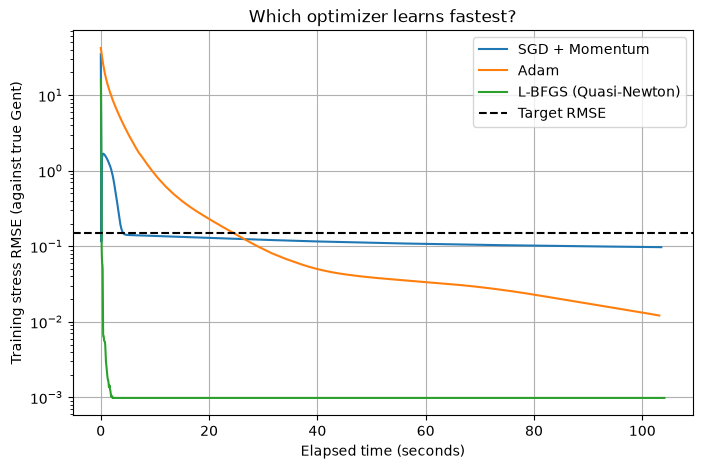

In [33]:
# Graph 1: error vs wall-clock time (the most useful speed comparison)
plt.figure(figsize=(8, 5))
for name, r in results.items():
    plt.semilogy(r['time'], r['train'], label=name)
plt.axhline(target_rmse, color='black', linestyle='--', label='Target RMSE')
plt.xlabel('Elapsed time (seconds)')
plt.ylabel('Training stress RMSE (against true Gent)')
plt.title('Which optimizer learns fastest?')
plt.legend()
plt.grid(True)
plt.show()


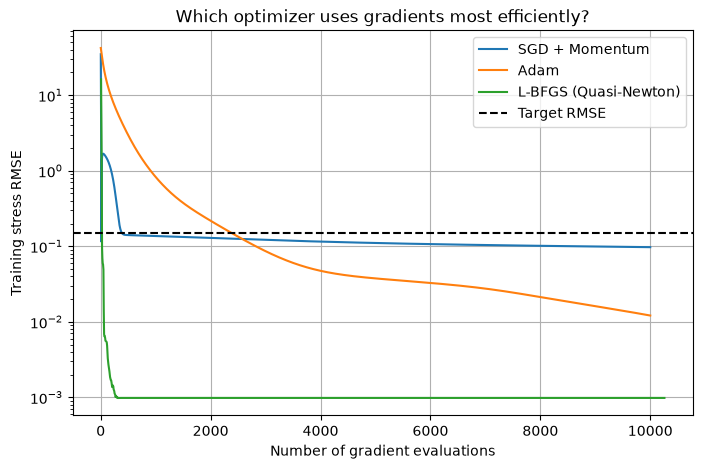

In [34]:
# Graph 2: error vs gradient evaluations (fairer than comparing epochs)
plt.figure(figsize=(8, 5))
for name, r in results.items():
    plt.semilogy(r['evaluations'], r['train'], label=name)
plt.axhline(target_rmse, color='black', linestyle='--', label='Target RMSE')
plt.xlabel('Number of gradient evaluations')
plt.ylabel('Training stress RMSE')
plt.title('Which optimizer uses gradients most efficiently?')
plt.legend()
plt.grid(True)
plt.show()


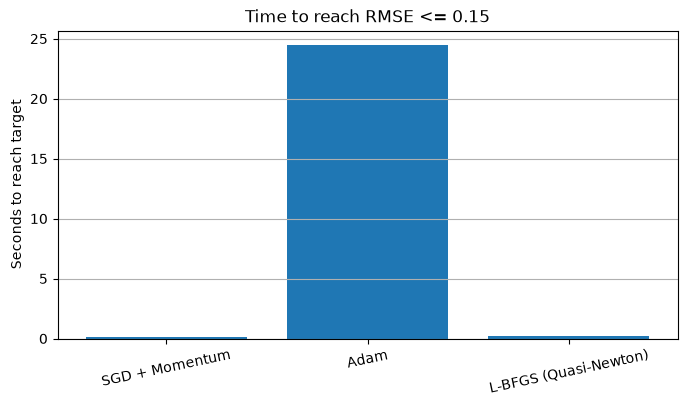

In [35]:
# Graph 3: time needed to reach the chosen error target
names, seconds = [], []
for name, r in results.items():
    hit = next((i for i, e in enumerate(r['train']) if e <= target_rmse), None)
    if hit is not None:
        names.append(name)
        seconds.append(r['time'][hit])
    else:
        print(f'{name}: target RMSE {target_rmse} not reached')

if names:
    plt.figure(figsize=(8, 4))
    plt.bar(names, seconds)
    plt.ylabel('Seconds to reach target')
    plt.title(f'Time to reach RMSE <= {target_rmse}')
    plt.xticks(rotation=12)
    plt.grid(axis='y')
    plt.show()


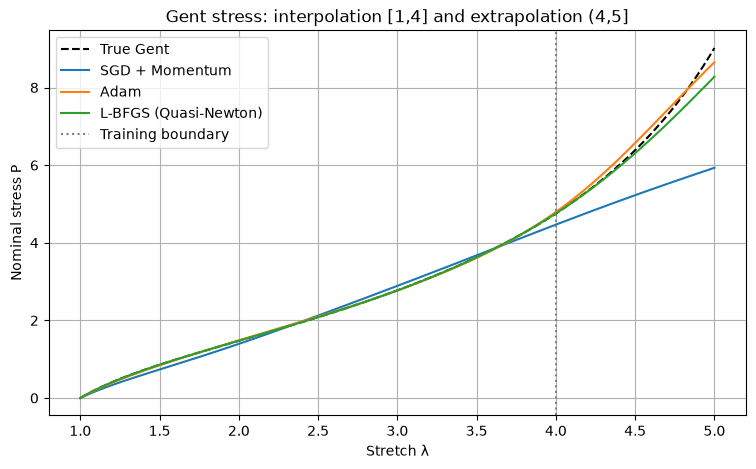

In [36]:
# Graph 4: learned stress-stretch curves (interpolation and extrapolation)
lamda_plot = torch.linspace(1.0, 5.0, 400).reshape(-1, 1)
P_true_plot = gent_stress_function(lamda_plot, mu, jm)

plt.figure(figsize=(9, 5))
plt.plot(lamda_plot.numpy(), P_true_plot.numpy(), 'k--', label='True Gent')
for name, model in models.items():
    P_pred = predict_stress(model, lamda_plot).detach()
    plt.plot(lamda_plot.numpy(), P_pred.numpy(), label=name)
plt.axvline(4.0, color='gray', linestyle=':', label='Training boundary')
plt.xlabel('Stretch λ')
plt.ylabel('Nominal stress P')
plt.title('Gent stress: interpolation [1,4] and extrapolation (4,5]')
plt.legend()
plt.grid(True)
plt.show()


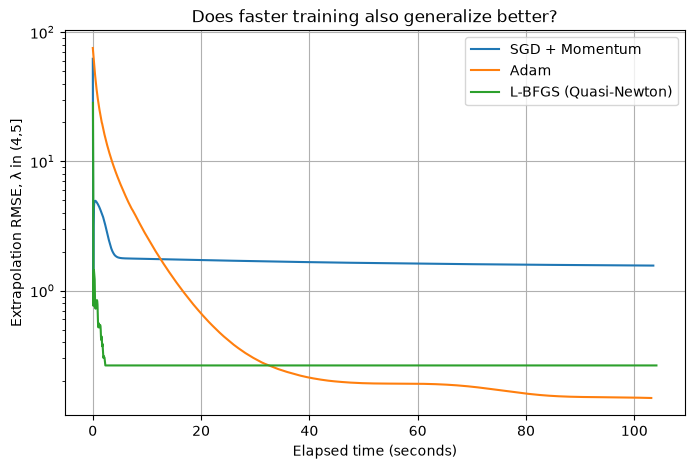

In [37]:
# Graph 5: extrapolation error vs time
plt.figure(figsize=(8, 5))
for name, r in results.items():
    plt.semilogy(r['time'], r['test'], label=name)
plt.xlabel('Elapsed time (seconds)')
plt.ylabel('Extrapolation RMSE, λ in (4,5]')
plt.title('Does faster training also generalize better?')
plt.legend()
plt.grid(True)
plt.show()


### How to read the plots

- **Graph 1:** Best direct comparison of training speed. Lower and further left is better.
- **Graph 2:** Shows optimization efficiency. L-BFGS may use several gradients in one step.
- **Graph 3:** Compare target times only for methods that actually reached the target.
- **Graph 4:** Check physical reconstruction and behavior beyond the training range.
- **Graph 5:** A low training error does not guarantee good extrapolation.

**Notes:** The model retains the original Gent stress equation and softplus energy architecture. Random hard-concrete gates and the sparsity penalty are deliberately removed. This benchmark uses the same noisy dataset for all three optimizers, but evaluates against the noiseless Gent law. Learning rates are simple starting choices, not individually tuned.
